# 03 · Продуктовая аналитика: юнит-экономика, дерево метрик, гипотеза и A/B-тест

Задание: посчитать юнит-экономику по продуктам → найти точки роста → построить дерево метрик →
сформулировать гипотезу → описать A/B-тест длительностью **не больше 2 недель**.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # обратная совместимость типов pandas, на расчёты не влияет
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import json

import numpy as np
import statsmodels.formula.api as smf
import pandas as pd
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

sys.path.insert(0, str(Path.cwd().parent / "src"))
import cleaning as etl
import metrics as M
import viz
from viz import PRIMARY, ACCENT, GOOD, MUTED, save, pct_axis, eur_axis

viz.set_style()
pd.set_option("display.width", 200)

data = etl.load_clean()
deals, calls, spend = data["Deals"], data["Calls"], data["Spend"]
PRODUCTS = ["Digital Marketing", "UX/UI Design", "Web Developer"]

## 1. Юнит-экономика по продуктам

**Юнит** — лид (UA). Период — весь датасет (07.2023–06.2024).

| Метрика | Формула | Смысл |
|---|---|---|
| UA | число лидов | User Acquisition |
| B | студенты | Buyers |
| C1 | B / UA | конверсия в покупателя |
| T | число платежей (рассрочка: 1 платёж/мес. обучения; разовая оплата: 1) | Transactions |
| Revenue | признанная выручка: цена курса / длительность × отученные месяцы | |
| AOV | Revenue / T | средний платёж |
| APC | T / B | среднее число платежей на студента |
| AC | рекламный бюджет | Acquisition Cost |
| CPA | AC / UA | стоимость лида |
| CAC | AC / B | стоимость студента |
| ARPU | Revenue / UA = C1 · AOV · APC | доход на лида |
| CLTV | AOV · APC | доход на студента |
| CM | Revenue − AC | маржинальная прибыль (до затрат на обучение) |
| ROMI | CM / AC | окупаемость маркетинга |

**Допущения (важно для защиты):**
1. У 82% лидов продукт не указан (не дошли до консультации). Поэтому лиды и рекламный бюджет распределяем
   по продуктам **пропорционально доле продукта среди лидов, у которых он указан**. Альтернатива — считать
   UA только по лидам с продуктом — завысила бы C1 в 5 раз и занизила CPA.
2. Себестоимости обучения (зарплаты преподавателей, платформа) в данных нет → CM считается как
   маржинальная прибыль *после маркетинга*. Это верхняя граница реальной маржи.
3. Выручка — признанная **к дате выгрузки**, только за отученные месяцы (раздел 1.1): многие студенты
   продолжают учиться, поэтому для свежих когорт Revenue и APC занижены.

In [2]:
known = deals[deals["product"].isin(PRODUCTS)]
share = known["product"].value_counts(normalize=True).reindex(PRODUCTS)
UA_total, AC_total = len(deals), spend["spend"].sum()

stud = deals[deals["is_student"] & deals["product"].isin(PRODUCTS)]
ue = pd.DataFrame(index=PRODUCTS)
ue["UA"] = share * UA_total
ue["B"] = stud.groupby("product", observed=True).size().reindex(PRODUCTS)
ue["T"] = stud.groupby("product", observed=True)["payments_count"].sum().reindex(PRODUCTS)
ue["Revenue"] = stud.groupby("product", observed=True)["revenue"].sum().reindex(PRODUCTS)
ue["AC"] = share * AC_total


def add_ratios(t: pd.DataFrame) -> pd.DataFrame:
    t = t.copy()
    t["C1"] = t["B"] / t["UA"]
    t["AOV"] = t["Revenue"] / t["T"]
    t["APC"] = t["T"] / t["B"]
    t["CPA"] = t["AC"] / t["UA"]
    t["CAC"] = t["AC"] / t["B"]
    t["ARPU"] = t["Revenue"] / t["UA"]
    t["CLTV"] = t["AOV"] * t["APC"]
    t["CM"] = t["Revenue"] - t["AC"]
    t["CM_per_UA"] = t["CM"] / t["UA"]
    t["ROMI"] = t["CM"] / t["AC"]
    return t


ue.loc["Total (3 products)"] = ue.sum()
ue = add_ratios(ue)
fmt = {"UA": "{:,.0f}", "B": "{:,.0f}", "T": "{:,.0f}", "Revenue": "€{:,.0f}", "AC": "€{:,.0f}",
       "C1": "{:.2%}", "AOV": "€{:,.0f}", "APC": "{:.2f}", "CPA": "€{:.2f}", "CAC": "€{:,.0f}",
       "ARPU": "€{:.0f}", "CLTV": "€{:,.0f}", "CM": "€{:,.0f}", "CM_per_UA": "€{:.0f}", "ROMI": "{:.0%}"}
ue.style.format(fmt)

,UA,B,T,Revenue,AC,C1,AOV,APC,CPA,CAC,ARPU,CLTV,CM,CM_per_UA,ROMI
Digital Marketing,"10,957",473,"2,768","€2,146,764","€82,655",4.32%,€776,5.85,€7.54,€175,€196,"€4,539","€2,064,109",€188,2497%
UX/UI Design,"5,683",227,"1,113","€855,655","€42,872",3.99%,€769,4.90,€7.54,€189,€151,"€3,769","€812,782",€143,1896%
Web Developer,"3,181",137,474,"€341,933","€23,997",4.31%,€721,3.46,€7.54,€175,€107,"€2,496","€317,937",€100,1325%
Total (3 products),"19,822",837,"4,355","€3,344,352","€149,523",4.22%,€768,5.20,€7.54,€179,€169,"€3,996","€3,194,828",€161,2137%


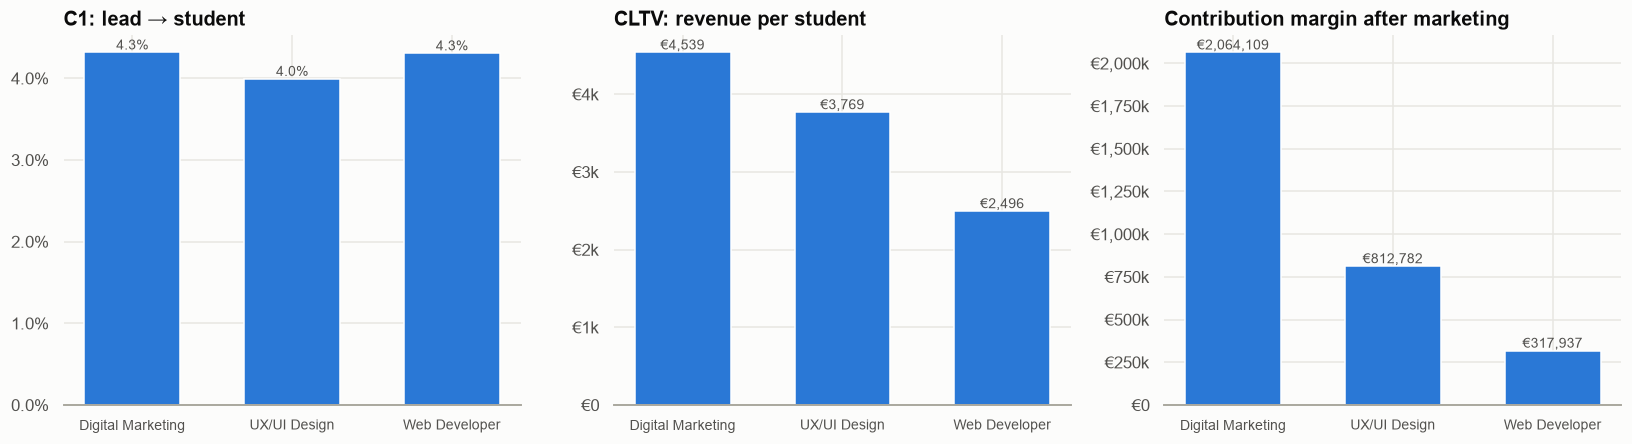

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
p = ue.loc[PRODUCTS]
for ax, col, title, f in [(axes[0], "C1", "C1: lead → student", "pct"),
                          (axes[1], "CLTV", "CLTV: revenue per student", "eur"),
                          (axes[2], "CM", "Contribution margin after marketing", "eur")]:
    ax.bar(p.index, p[col], color=PRIMARY, width=0.6)
    ax.set_title(title); ax.tick_params(axis="x", labelsize=9)
    pct_axis(ax, decimals=1) if f == "pct" else eur_axis(ax)
    for i, v in enumerate(p[col]):
        ax.text(i, v, f"{v:.1%}" if f == "pct" else f"€{v:,.0f}", ha="center", va="bottom", fontsize=9, color=viz.TEXT_2)
plt.tight_layout(); save(fig, "03_unit_economics"); plt.show()

**Чтение юнит-экономики:**
- Все три продукта прибыльны после маркетинга: CAC (≈ €180) в 14–26 раз меньше CLTV. Маркетинг сейчас
  не ограничивает бизнес — ограничивает **конверсия**: из 100 лидов покупают ~4.
- **Digital Marketing** — главный источник прибыли: самый высокий CLTV и наибольшее число студентов.
- **Web Developer** — CLTV вдвое ниже (6-месячный курс дешевле), при той же стоимости лида.
- APC ≈ 5 платежей: студенты в среднем на середине курса — выручка будет расти по мере продолжения обучения.

### 1.1 Признание выручки: деньги получены ≠ выручка заработана

По немецкому праву (договор на обучение, § 611 BGB; принцип реализации, § 252 HGB) школа зарабатывает выручку
только за месяцы, которые студент уже отучился. Предоплата за будущие месяцы — это обязательство
(Rechnungsabgrenzung / аванс), а не прибыль: у отчисленного студента её нужно вернуть.

- `cash_received` — деньги, полученные к дате выгрузки (первый платёж + помесячные платежи);
- `revenue` — признанная выручка = цена курса / длительность × отученные месяцы (её используем везде в проекте);
- `prepaid` = `cash_received` − `revenue` > 0 — аванс за будущие месяцы;
- `refund_due` — аванс отчисленных студентов, сумма к возврату.

Статус студента в CRM не записан, поэтому он **оценивается**: закончил — отучился весь курс; отчислен — отучился
меньше месяцев, чем прошло с оплаты, с запасом в 1 месяц; у 314 студентов нет даты оплаты, их статус неизвестен.

In [4]:
s = deals[deals["is_student"]]
rec = s.groupby("student_status").agg(students=("id", "size"), cash_received=("cash_received", "sum"),
                                      revenue=("revenue", "sum"), prepaid=("prepaid", "sum"),
                                      refund_due=("refund_due", "sum"))
rec.loc["Итого"] = rec.sum()
rec.style.format({"students": "{:,.0f}", **{c: "€{:,.0f}" for c in ["cash_received", "revenue", "prepaid", "refund_due"]}})

,students,cash_received,revenue,prepaid,refund_due
student_status,,,,,
active,398,"€1,415,285","€1,312,244","€107,869",€0
dropout,54,"€85,460","€72,532","€13,638","€13,638"
finished,71,"€408,500","€408,500",€0,€0
unknown,314,"€1,669,100","€1,551,076","€122,833",€0
Итого,837,"€3,578,345","€3,344,352","€244,341","€13,638"


**Вывод:** из €3.58 млн полученных денег выручкой признаются €3.34 млн. €244k — авансы за будущие месяцы, из них
€200k — разовые оплаты всего курса вперёд. Отчисленным (по оценке 54 студента) нужно вернуть около €14k: эти
деньги нельзя показывать как прибыль. Остальные €231k станут выручкой, когда студенты отучатся оплаченные месяцы,
или тоже уйдут в возврат, если они бросят учёбу. У 182 студентов, наоборот, оплачено на €10k меньше, чем отучено
(дебиторская задолженность).

## 2. Точки роста: анализ чувствительности
Увеличиваем каждую метрику на 10% и смотрим, как меняется CM. При росте UA рекламный бюджет растёт
пропорционально (CPA постоянен); рост C1, AOV, APC бюджета не требует.

,"ΔCM, €","ΔCM, %"
UA +10%,"€319,483",10.0%
C1 +10%,"€334,435",10.5%
AOV +10%,"€334,435",10.5%
APC +10%,"€334,435",10.5%
CPA −10%,"€14,952",0.5%


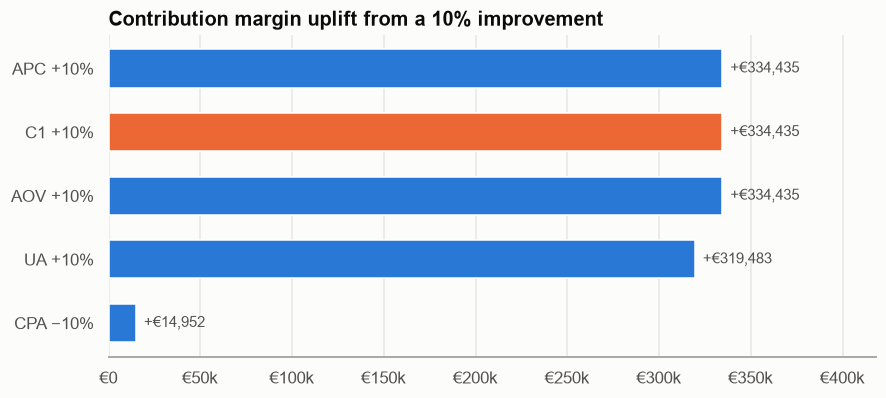

In [5]:
base = ue.loc["Total (3 products)"]


def cm(UA, C1, AOV, APC, CPA):
    return UA * C1 * AOV * APC - UA * CPA


m0 = dict(UA=base["UA"], C1=base["C1"], AOV=base["AOV"], APC=base["APC"], CPA=base["CPA"])
cm0 = cm(**m0)
sens = {}
for k in ["UA", "C1", "AOV", "APC"]:
    m = m0.copy(); m[k] *= 1.10
    sens[k] = cm(**m) - cm0
m = m0.copy(); m["CPA"] *= 0.90
sens["CPA −10%"] = cm(**m) - cm0
sens = pd.Series(sens).rename({"UA": "UA +10%", "C1": "C1 +10%", "AOV": "AOV +10%", "APC": "APC +10%"})
sens_df = pd.DataFrame({"ΔCM, €": sens, "ΔCM, %": sens / cm0})
display(sens_df.style.format({"ΔCM, €": "€{:,.0f}", "ΔCM, %": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(9, 3.8))
s = sens.sort_values()
ax.barh(s.index, s.values, color=[ACCENT if "C1" in i else PRIMARY for i in s.index], height=0.6)
eur_axis(ax, "x"); ax.set_title("Contribution margin uplift from a 10% improvement"); ax.grid(axis="y", visible=False)
for i, v in enumerate(s.values):
    ax.text(v, i, f"  +€{v:,.0f}", va="center", fontsize=10, color=viz.TEXT_2)
ax.set_xlim(0, s.max() * 1.25)
save(fig, "03_sensitivity"); plt.show()

**Выбор точки роста.** C1, AOV и APC дают одинаковый прирост CM (+€334k, +10.5% на каждые +10%), рост трафика —
меньше (+€319k: бюджет растёт вместе с ним), снижение CPA на 10% — всего +€15k (маркетинг уже дешёвый
относительно выручки: CAC €179 при CLTV €3 996).
Из трёх равных рычагов выбираем **C1**, потому что:
1. у C1 самый большой запас: 96% лидов теряются, 40% проигранных — «не отвечает / перестал отвечать»;
2. AOV и APC — это цена и длительность обучения, менять их рискованно (цена влияет на спрос, APC
   растёт само по мере обучения);
3. EDA показал конкретный механизм улучшения C1 — **скорость первого контакта**.

## 3. Дерево метрик

In [6]:
deals = M.add_contact_metrics(deals, calls)   # first_talk, reached_24h, is_AB, sla_bucket (src/metrics.py)

reached = deals["reached_24h"].mean()
ab_given_reached = deals.loc[deals["reached_24h"], "is_AB"].mean()
c1_ab = deals.loc[deals["is_AB"], "is_student"].mean()
c1_other = deals.loc[~deals["is_AB"], "is_student"].mean()
tree = f"""
CM (маржинальная прибыль) = €{base['CM']:,.0f}
├── Revenue = €{base['Revenue']:,.0f}
│   ├── UA (лиды) = {base['UA']:,.0f}
│   │   ├── платные каналы: бюджет AC = €{base['AC']:,.0f} / CPA €{base['CPA']:.2f}
│   │   └── бесплатные: Organic, CRM, Partnership
│   ├── C1 (лид → студент) = {base['C1']:.2%}   ◀── ТОЧКА РОСТА
│   │   ├── дозвон: разговор ≥30 с в первые 24 ч = {reached:.1%}   ◀── воздействуем гипотезой
│   │   │   └── SLA первого контакта (медиана {deals['sla_sec'].median() / 3600:.1f} ч)
│   │   ├── квалификация: доля A+B среди дозвонившихся = {ab_given_reached:.1%}
│   │   └── закрытие: C1 у лидов A+B = {c1_ab:.1%}, у остальных = {c1_other:.2%}
│   ├── AOV (средний платёж) = €{base['AOV']:,.0f}
│   └── APC (платежей на студента) = {base['APC']:.2f}
└── AC (маркетинг) = €{base['AC']:,.0f}
"""
print(tree)


CM (маржинальная прибыль) = €3,194,828
├── Revenue = €3,344,352
│   ├── UA (лиды) = 19,822
│   │   ├── платные каналы: бюджет AC = €149,523 / CPA €7.54
│   │   └── бесплатные: Organic, CRM, Partnership
│   ├── C1 (лид → студент) = 4.22%   ◀── ТОЧКА РОСТА
│   │   ├── дозвон: разговор ≥30 с в первые 24 ч = 43.1%   ◀── воздействуем гипотезой
│   │   │   └── SLA первого контакта (медиана 5.5 ч)
│   │   ├── квалификация: доля A+B среди дозвонившихся = 15.8%
│   │   └── закрытие: C1 у лидов A+B = 23.7%, у остальных = 2.09%
│   ├── AOV (средний платёж) = €768
│   └── APC (платежей на студента) = 5.20
└── AC (маркетинг) = €149,523



Та же структура схемой. Верхние уровни раскладываются точно: **CM = Revenue − AC**,
**Revenue = UA × C1 × AOV × APC**. Ветка C1 разложена по шагам воронки: их произведение даёт долю лидов, ставших
студентами. Оранжевым выделен путь, на который действует гипотеза: скорость первого ответа → разговор → C1 → выручка → маржа.

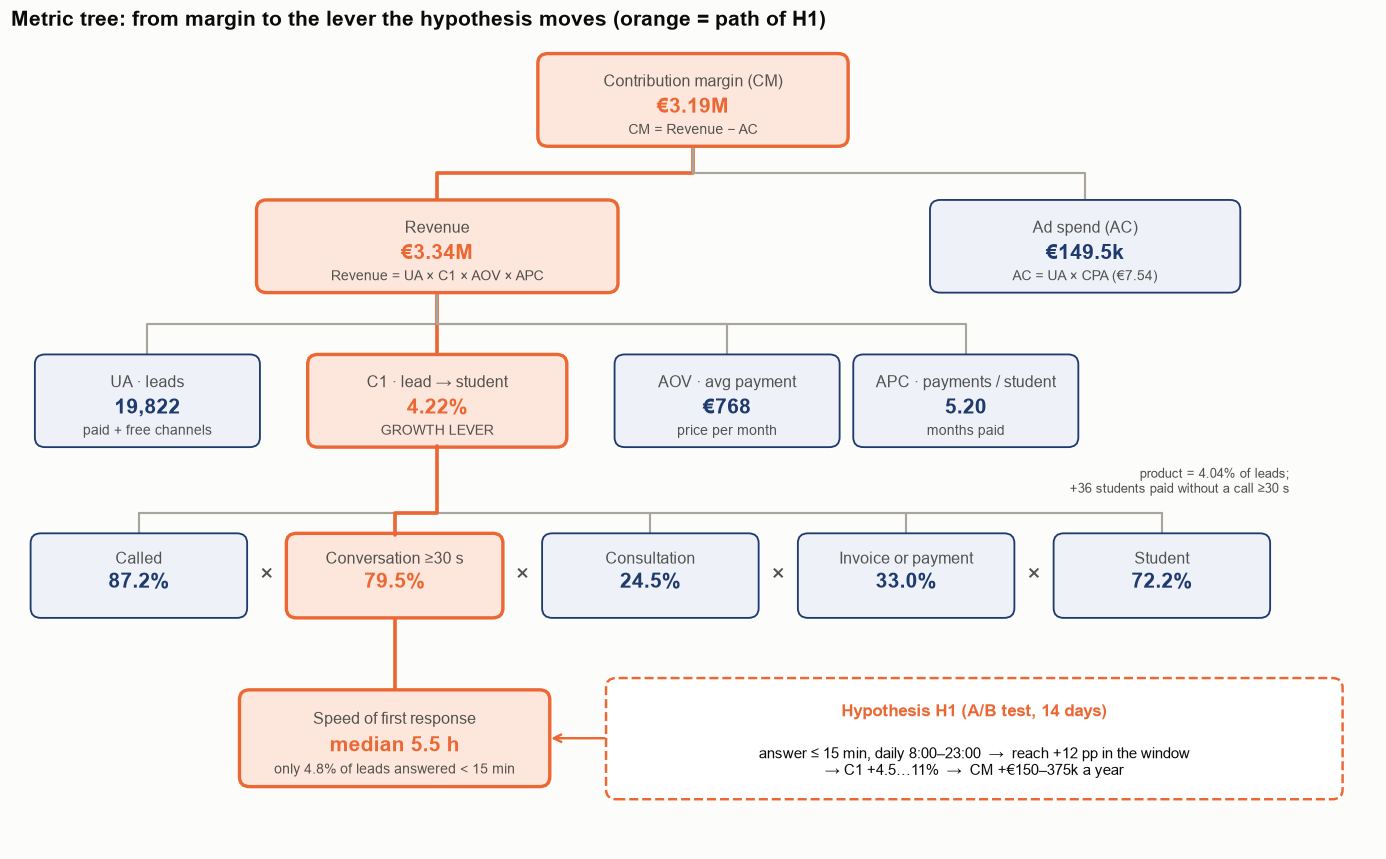

In [7]:
from matplotlib.patches import FancyBboxPatch

fun = M.funnel(deals, calls)
step = fun.iloc[:, 2]                      # step conversion (column name depends on M.set_lang)
fast_share = deals["sla_bucket"].eq("< 15 min").mean()
h1 = M.speed_test_design(deals).loc[M.CHOSEN_WINDOW].iloc[4]   # expected reach effect in the window, pp

fig, ax = plt.subplots(figsize=(16, 9.6))
ax.set_xlim(0, 16); ax.set_ylim(0, 10); ax.axis("off")
NAVY, PALE, HOT = "#1f3b6e", "#eef2f8", "#fde7dd"


def box(x, y, w, h, title, value, note="", hot=False):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=HOT if hot else PALE, ec=ACCENT if hot else NAVY, lw=2.2 if hot else 1.2))
    ax.text(x, y + h * 0.2, title, ha="center", va="center", fontsize=10.5, color=viz.TEXT_2)
    ax.text(x, y - h * 0.08, value, ha="center", va="center", fontsize=14, fontweight="bold",
            color=ACCENT if hot else NAVY)
    if note:
        ax.text(x, y - h * 0.34, note, ha="center", va="center", fontsize=9, color=viz.TEXT_2)


def link(x1, y1, x2, y2, hot=False):
    ym = (y1 + y2) / 2
    ax.plot([x1, x1, x2, x2], [y1, ym, ym, y2], color=ACCENT if hot else MUTED, lw=2.4 if hot else 1.4,
            zorder=0, solid_capstyle="round")


# level 0–1: money
box(8, 9.2, 3.6, 1.1, "Contribution margin (CM)", f"€{base['CM'] / 1e6:,.2f}M", "CM = Revenue − AC", hot=True)
box(5, 7.4, 4.2, 1.1, "Revenue", f"€{base['Revenue'] / 1e6:,.2f}M", "Revenue = UA × C1 × AOV × APC", hot=True)
box(12.6, 7.4, 3.6, 1.1, "Ad spend (AC)", f"€{base['AC'] / 1e3:,.1f}k", f"AC = UA × CPA (€{base['CPA']:.2f})")
link(8, 8.65, 5, 7.95, hot=True); link(8, 8.65, 12.6, 7.95)

# level 2: revenue factors
x2 = {"UA": 1.6, "C1": 5.0, "AOV": 8.4, "APC": 11.2}
box(x2["UA"], 5.5, 2.6, 1.1, "UA · leads", f"{base['UA']:,.0f}", "paid + free channels")
box(x2["C1"], 5.5, 3.0, 1.1, "C1 · lead → student", f"{base['C1']:.2%}", "GROWTH LEVER", hot=True)
box(x2["AOV"], 5.5, 2.6, 1.1, "AOV · avg payment", f"€{base['AOV']:,.0f}", "price per month")
box(x2["APC"], 5.5, 2.6, 1.1, "APC · payments / student", f"{base['APC']:.2f}", "months paid")
for k, x in x2.items():
    link(5, 6.85, x, 6.05, hot=(k == "C1"))

# level 3: C1 as a product of funnel steps
steps = [("Called", step.iloc[1]), ("Conversation ≥30 s", step.iloc[2]), ("Consultation", step.iloc[3]),
         ("Invoice or payment", step.iloc[4]), ("Student", step.iloc[5])]
xs = [1.5, 4.5, 7.5, 10.5, 13.5]
for (name, v), x in zip(steps, xs):
    box(x, 3.35, 2.5, 1.0, name, f"{v:.1%}", hot=(name == "Conversation ≥30 s"))
for a, b in zip(xs[:-1], xs[1:]):
    ax.text((a + b) / 2, 3.35, "×", ha="center", va="center", fontsize=16, color=viz.TEXT_2)
BUS = 4.12   # C1 → bus → every funnel step; the hypothesis path (orange) goes to the conversation step
ax.plot([xs[0], xs[-1]], [BUS, BUS], color=MUTED, lw=1.4, zorder=0)
for x in xs:
    ax.plot([x, x], [BUS, 3.85], color=MUTED, lw=1.4, zorder=0)
ax.plot([x2["C1"], x2["C1"], xs[1], xs[1]], [4.95, BUS, BUS, 3.85], color=ACCENT, lw=2.4, zorder=1)
ax.text(15.0, 4.32, f"product = {step.iloc[1:].prod():.2%} of leads;\n+36 students paid without a call ≥30 s",
        ha="right", va="bottom", fontsize=8.5, color=viz.TEXT_2)

# level 4: driver and hypothesis
box(xs[1], 1.35, 3.6, 1.15, "Speed of first response", f"median {deals['sla_sec'].median() / 3600:.1f} h",
    f"only {fast_share:.1%} of leads answered < 15 min", hot=True)
link(xs[1], 2.85, xs[1], 1.93, hot=True)
ax.add_patch(FancyBboxPatch((7.0, 0.62), 8.6, 1.45, boxstyle="round,pad=0.02,rounding_size=0.12",
                            fc="white", ec=ACCENT, lw=1.6, ls="--"))
ax.text(11.3, 1.62, "Hypothesis H1 (A/B test, 14 days)", ha="center", fontsize=11, fontweight="bold", color=ACCENT)
ax.text(11.3, 1.05, f"answer ≤ 15 min, daily 8:00–23:00  →  reach +{h1:.0f} pp in the window\n"
        "→ C1 +4.5…11%  →  CM +€150–375k a year", ha="center", va="center", fontsize=10, color=viz.TEXT)
ax.annotate("", xy=(7.0, 1.35), xytext=(xs[1] + 1.8, 1.35), arrowprops=dict(arrowstyle="<-", color=ACCENT, lw=1.6))
ax.set_title("Metric tree: from margin to the lever the hypothesis moves (orange = path of H1)",
             loc="left", fontsize=14, color=viz.TEXT)
save(fig, "03_metric_tree"); plt.show()

Дерево раскладывает CM до операционных метрик, на которые отдел продаж может влиять ежедневно.
Цепочка воздействия гипотезы: **SLA ↓ → дозвон ↑ → квалифицированные лиды ↑ → C1 ↑ → Revenue ↑ → CM ↑**.

## 4. Гипотеза

Из EDA (ноутбук 02, раздел 7):

In [8]:
evidence = deals.groupby("sla_bucket", observed=True).agg(
    leads=("id", "size"), reached_24h=("reached_24h", "mean"), share_AB=("is_AB", "mean"), C1=("is_student", "mean"))
evidence.style.format({"reached_24h": "{:.1%}", "share_AB": "{:.1%}", "C1": "{:.1%}"})

,leads,reached_24h,share_AB,C1
sla_bucket,,,,
< 15 min,950,77.1%,21.2%,6.6%
15–60 min,2385,65.2%,13.9%,6.0%
1–4 h,3287,62.3%,12.6%,5.5%
4–24 h,6615,55.8%,10.7%,5.2%
> 24 h,1758,1.4%,13.6%,4.6%


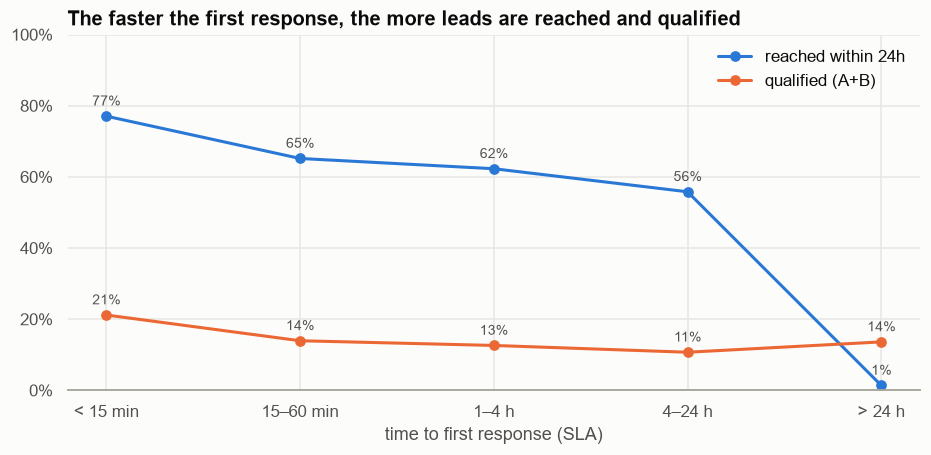

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(evidence))
ax.plot(x, evidence["reached_24h"], marker="o", color=PRIMARY, label="reached within 24h")
ax.plot(x, evidence["share_AB"], marker="o", color=ACCENT, label="qualified (A+B)")
ax.set_xticks(x, evidence.index.astype(str)); pct_axis(ax)
for xi, (r, q) in enumerate(zip(evidence["reached_24h"], evidence["share_AB"])):
    ax.text(xi, r + 0.03, f"{r:.0%}", ha="center", fontsize=9, color=viz.TEXT_2)
    ax.text(xi, q + 0.03, f"{q:.0%}", ha="center", fontsize=9, color=viz.TEXT_2)
ax.set_title("The faster the first response, the more leads are reached and qualified")
ax.set_xlabel("time to first response (SLA)"); ax.legend(frameon=False); ax.set_ylim(0, 1)
save(fig, "03_hypothesis_evidence"); plt.show()

**Корректное сравнение.** Лиды из корзины «> 24 h» по построению не могут получить разговор в первые 24 ч
(дозвон 1.4%), поэтому сравниваем быстрый ответ только с ответом от 15 минут до 24 часов.
Проверяем, не объясняется ли разница временем заявки (ночью отвечают медленнее) или источником.

In [10]:
fast = deals["sla_bucket"].eq("< 15 min")
slow = deals["sla_bucket"].isin(M.SLOW)
work = deals["created_time"].dt.hour.between(9, 17) & (deals["created_time"].dt.dayofweek < 5)
check = {"все лиды": deals.index == deals.index, "рабочее время (пн–пт, 9–18)": work}
for s in ["Facebook Ads", "Google Ads"]:
    check[s] = deals["source"].eq(s)
robust = pd.DataFrame({
    name: {"< 15 мин": deals.loc[mask & fast, "reached_24h"].mean(),
           "15 мин – 24 ч": deals.loc[mask & slow, "reached_24h"].mean()}
    for name, mask in check.items()}).T
robust["разрыв, п.п."] = (robust["< 15 мин"] - robust["15 мин – 24 ч"]) * 100
robust.style.format({"< 15 мин": "{:.1%}", "15 мин – 24 ч": "{:.1%}", "разрыв, п.п.": "{:+.1f}"})

,< 15 мин,15 мин – 24 ч,"разрыв, п.п."
все лиды,77.1%,59.3%,+17.7
"рабочее время (пн–пт, 9–18)",77.9%,62.3%,+15.6
Facebook Ads,80.6%,60.5%,+20.0
Google Ads,77.6%,61.0%,+16.6


Разрыв 16–20 п.п. сохраняется в рабочее время и внутри каждого крупного источника — эффект не сводится к
ночным заявкам или к структуре каналов. Проверим это строже: логистическая регрессия учитывает **одновременно**
источник, час и день недели заявки, месяц и менеджера. Если быстрый ответ — это просто признак «сильного»
менеджера или «горячего» канала, эффект после контроля должен исчезнуть.

In [11]:
x = deals[deals["sla_bucket"].isin(["< 15 min", *M.SLOW])].copy()
x["fast"] = x["sla_bucket"].eq("< 15 min").astype(int)
x["reached"] = x["reached_24h"].astype(int)
x["hour"] = x["created_time"].dt.hour.astype(str)
x["dow"] = x["created_time"].dt.dayofweek.astype(str)
x["mon"] = x["month"].dt.strftime("%Y-%m")
for col, src in [("owner", "deal_owner_name"), ("src", "source")]:
    v = x[src].astype(str)
    x[col] = v.where(v.map(v.value_counts()) >= 50, "other")   # редкие категории объединяем

logit = smf.logit("reached ~ fast + C(src) + C(hour) + C(dow) + C(mon) + C(owner)", x).fit(disp=0, maxiter=200)
me = logit.get_margeff(at="overall").summary_frame().loc["fast"]
raw_gap = x.loc[x["fast"] == 1, "reached"].mean() - x.loc[x["fast"] == 0, "reached"].mean()
adj_gap = me["dy/dx"]
pd.Series({"разрыв без контроля, п.п.": f"{raw_gap * 100:+.1f}",
           "разрыв с контролем (средний предельный эффект), п.п.": f"{adj_gap * 100:+.1f}",
           "95% ДИ, п.п.": f"[{me['Conf. Int. Low'] * 100:+.1f}; {me['Cont. Int. Hi.'] * 100:+.1f}]",
           "отношение шансов": f"{np.exp(logit.params['fast']):.2f}",
           "p-value": f"{logit.pvalues['fast']:.1e}",
           "лидов в модели": f"{len(x):,}"}, name="fast (< 15 мин) → дозвон за 24 ч").to_frame()

,fast (< 15 мин) → дозвон за 24 ч
"разрыв без контроля, п.п.",+17.7
"разрыв с контролем (средний предельный эффект), п.п.",+19.0
"95% ДИ, п.п.",[+15.2; +22.8]
отношение шансов,2.33
p-value,2.9e-22
лидов в модели,"13,237"


С учётом источника, времени заявки, месяца и менеджера разрыв почти не меняется (+19 п.п., 95% ДИ ≈ +15…+23).
Значит, связь скорости и дозвона не объясняется этими факторами. Остаются ненаблюдаемые причины (например,
менеджер быстрее берёт заявку, которая выглядит «горячей»), поэтому окончательный ответ даст только A/B-тест.

> **Гипотеза (H1).** Если каждому новому лиду в течение 1 минуты автоматически назначать свободного менеджера
> с push-уведомлением и отправлять клиенту сообщение в WhatsApp/SMS («Менеджер позвонит в течение 15 минут»),
> а менеджер обязан позвонить **в течение 15 минут ежедневно с 8:00 до 23:00** (сменный график),
> **то доля лидов, с которыми состоялся разговор в первые 24 часа, вырастет как минимум на 10 п.п.**,
> **потому что** клиент ещё «тёплый» и ждёт звонка: в данных лиды с ответом < 15 мин дозваниваются в 77% случаев
> против 59% при ответе от 15 минут до 24 часов (+19 п.п. с учётом источника, времени, месяца и менеджера).

**Почему окно 8:00–23:00, а не рабочее время.** Заявки приходят равномерно с 8 утра до 23 часов, в том числе
в выходные: в будни с 9 до 18 приходит только 41% лидов. Правило, которое действует только в рабочее время,
не затронет большинство потока, и эффект на всех лидах получится слишком маленьким для теста (раздел 5).

- **Метрика продукта, на которую воздействуем:** C1 (через дозвон и квалификацию).
- **Первичная метрика теста:** `reached_24h` — доля лидов с разговором ≥ 30 секунд в первые 24 часа.
  Выбрана потому, что: (а) она измерима за 1 день, а оплата — в среднем через 17+ дней и за 2 недели её не
  набрать; (б) она напрямую связана с C1 (см. дерево метрик).
- **Вторичные метрики:** медианный SLA, доля лидов A+B, доля `Lost` с причиной «не отвечает».
- **Метрика внедрения (проверяем первой):** доля лидов группы B, которым позвонили ≤ 15 мин. Если она ниже
  порога из раздела 5, тест не сможет показать эффект, даже если гипотеза верна.
- **Отложенная метрика:** C1 по когортам теста — отслеживаем через 45 дней после окончания.
- **Guardrail-метрики (не должны ухудшиться):** доля лидов `Non target`, число звонков на менеджера в день
  (нагрузка), доля жалоб/отписок от сообщений.
- **H0:** доли `reached_24h` в группах A и B равны.

## 5. Дизайн A/B-теста: срок зафиксирован — 14 дней

**Тест не проводился:** в выгрузке CRM нет данных эксперимента, поэтому ниже — только дизайн. По условию срок
теста не больше 2 недель, поэтому идём от срока: фиксируем 14 дней → считаем, сколько лидов наберётся →
считаем **MDE** (минимальный эффект, который тест сможет заметить при α = 0.05 и мощности 80%). Тест имеет смысл,
только если ожидаемый эффект не меньше MDE.

**Ожидаемый эффект считаем из данных, а не задаём «на глаз».** Внутри окна действия правила лиды, которым сейчас
отвечают за 15 минут – 24 часа, получают дозвон быстрых лидов (77%). Лиды без SLA и с ответом позже суток считаем
незатронутыми — это консервативная оценка. Baseline — дозвон **всех** лидов окна, а не только медленных: в тест
попадают все новые лиды, и контрольная группа будет такой же смесью.

,доля лидов в окне,лидов в окне в день,лидов на группу за 14 дней,baseline дозвона в окне,"ожидаемый эффект в окне, п.п.","MDE в окне, п.п.","эффект на всех лидах, п.п.","MDE на всех лидах, п.п.",тест в окне имеет смысл
пн–пт 9:00–18:00 (текущий график),41%,30,212,44.0%,+11.0,+13.6,+4.5,+8.7,False
пн–пт 8:00–21:00,58%,43,301,41.8%,+11.5,+11.4,+6.7,+8.7,True
ежедневно 8:00–21:00,74%,55,386,42.2%,+11.7,+10.1,+8.7,+8.7,True
ежедневно 8:00–23:00,85%,63,442,42.2%,+12.2,+9.4,+10.4,+8.7,True


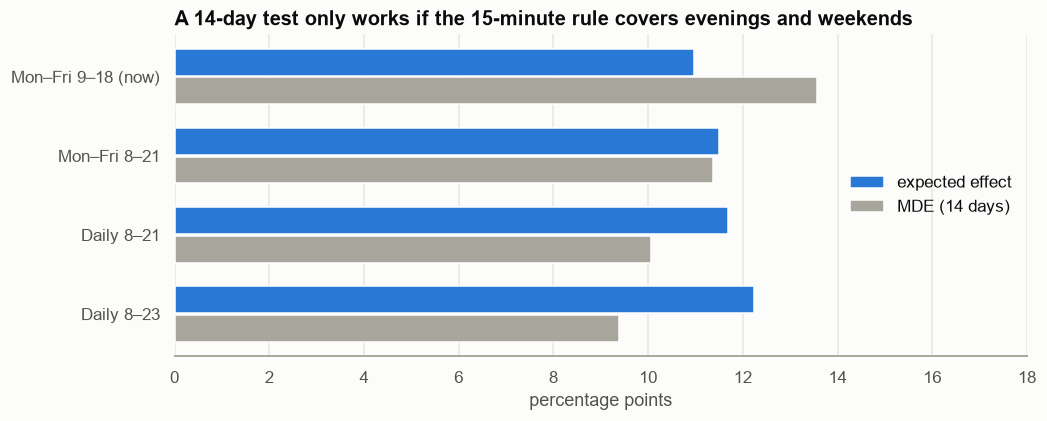

In [12]:
recent = deals[deals["created_time"] >= M.RECENT_FROM]
n_days = recent["created_time"].dt.normalize().nunique()
leads_per_day = len(recent) / n_days
alpha, power, TEST_DAYS = M.ALPHA, M.POWER, M.TEST_DAYS
mde_for = M.mde

options = M.speed_test_design(deals)
display(options.style.format({"доля лидов в окне": "{:.0%}", "лидов в окне в день": "{:.0f}",
                              "лидов на группу за 14 дней": "{:,.0f}", "baseline дозвона в окне": "{:.1%}",
                              **{c: "{:+.1f}" for c in options.columns if "п.п." in c}}))

fig, ax = plt.subplots(figsize=(10, 3.8))
y = np.arange(len(options))[::-1]
ax.barh(y + 0.18, options["ожидаемый эффект в окне, п.п."], height=0.34, color=PRIMARY, label="expected effect")
ax.barh(y - 0.18, options["MDE в окне, п.п."], height=0.34, color=MUTED, label="MDE (14 days)")
ax.set_yticks(y, ["Mon–Fri 9–18 (now)", "Mon–Fri 8–21", "Daily 8–21", "Daily 8–23"])
ax.set_xlabel("percentage points"); ax.set_xlim(0, 18); ax.legend(frameon=False, loc="center right"); ax.grid(axis="y", visible=False)
ax.set_title("A 14-day test only works if the 15-minute rule covers evenings and weekends")
save(fig, "03_test_coverage"); plt.show()

In [13]:
W = M.CHOSEN_WINDOW
opt = options.loc[W]
breakeven = M.break_even_compliance(deals)
comp = pd.DataFrame({f"{c:.0%}": M.speed_test_design(deals, compliance=c).loc[W, ["ожидаемый эффект в окне, п.п.", "MDE в окне, п.п."]]
                     for c in [1.0, 0.9, 0.8, 0.7, 0.6]}).T
comp.index.name = "выполнение правила (доля B-лидов с звонком ≤ 15 мин)"
comp["тест заметит эффект"] = comp.iloc[:, 0] >= comp.iloc[:, 1]
display(comp.style.format({c: "{:+.1f}" for c in comp.columns[:2]}))

n_group = int(opt["лидов на группу за 14 дней"])
p_control = opt["baseline дозвона в окне"]
mde = opt["MDE в окне, п.п."] / 100
expected = opt["ожидаемый эффект в окне, п.п."] / 100
design = pd.Series({
    "Срок теста": f"{TEST_DAYS} дней (2 полные недели — учитывает недельную сезонность)",
    "Окно правила «звонок ≤ 15 мин»": f"{W} — {opt['доля лидов в окне']:.0%} лидов",
    "Анализируемая выборка": "лиды, созданные в окне (заранее зафиксировано в плане теста)",
    "Лидов в окне в день (с марта 2024)": f"{opt['лидов в окне в день']:.0f}",
    "Лидов на группу за 14 дней (50/50)": f"{n_group:,}",
    "Baseline reached_24h (контроль)": f"{p_control:.1%}",
    "α / мощность": f"{alpha} / {power:.0%}, двусторонний тест",
    "MDE за 14 дней": f"+{mde * 100:.1f} п.п. (с {p_control:.1%} до {p_control + mde:.1%})",
    "Ожидаемый эффект при полном выполнении": f"+{expected * 100:.1f} п.п.",
    "Минимальное выполнение правила": f"{breakeven:.0%} лидов группы B получают звонок ≤ 15 мин",
    "Вывод": ("ожидаемый эффект ≥ MDE — тест за 14 дней имеет смысл при выполнении правила ≥ "
              f"{breakeven:.0%}" if expected >= mde else "ожидаемый эффект < MDE — за 14 дней тест эффект не покажет"),
}, name="значение")
design.to_frame()

,"ожидаемый эффект в окне, п.п.","MDE в окне, п.п.",тест заметит эффект
выполнение правила (доля B-лидов с звонком ≤ 15 мин),,,
100%,+12.2,+9.4,True
90%,+11.0,+9.4,True
80%,+9.8,+9.4,True
70%,+8.6,+9.4,False
60%,+7.3,+9.4,False


,значение
Срок теста,14 дней (2 полные недели — учитывает недельную...
Окно правила «звонок ≤ 15 мин»,ежедневно 8:00–23:00 — 85% лидов
Анализируемая выборка,"лиды, созданные в окне (заранее зафиксировано ..."
Лидов в окне в день (с марта 2024),63
Лидов на группу за 14 дней (50/50),442
Baseline reached_24h (контроль),42.2%
α / мощность,"0.05 / 80%, двусторонний тест"
MDE за 14 дней,+9.4 п.п. (с 42.2% до 51.6%)
Ожидаемый эффект при полном выполнении,+12.2 п.п.
Минимальное выполнение правила,77% лидов группы B получают звонок ≤ 15 мин


**Что это значит.** При нынешнем графике (будни 9–18) правило затрагивает только 41% лидов: в окне тест
заметит лишь +13.6 п.п., а ожидаемый эффект +11.0 п.п. — тест за 14 дней провалился бы при любом результате.
Если звонить ежедневно с 8:00 до 23:00, окно покрывает 85% лидов, MDE падает до +9.4 п.п., а ожидаемый эффект
+12.2 п.п. Запас небольшой: при выполнении правила ниже ~77% тест снова теряет чувствительность. Поэтому:
1. перед стартом — 3 дня «технического пилота» маршрутизации, чтобы убедиться, что ≥ 80% лидов получают звонок ≤ 15 мин;
2. метрику выполнения смотрим каждый день теста (это не «подглядывание» в результат: первичную метрику не проверяем до 14-го дня).

**Условия проведения теста:**

| Параметр | Решение |
|---|---|
| Единица рандомизации | лид (новая заявка) |
| Разбиение | 50/50 по последней цифре ID сделки (чётная → B, нечётная → A) — детерминированно и проверяемо |
| Группа A (контроль) | текущий процесс распределения лидов |
| Группа B (тест) | автоназначение менеджера + push + авто-сообщение клиенту + правило «звонок ≤ 15 мин» с 8:00 до 23:00 (сменный график) |
| Кто участвует | все новые лиды из всех источников; анализ — лиды, созданные ежедневно с 8:00 до 23:00; одни и те же менеджеры работают с обеими группами |
| Длительность | ровно 14 дней, старт в понедельник; тест не останавливаем досрочно (проблема «подглядывания») |
| Проверка корректности | SRM-тест (хи-квадрат) на равенство размеров групп; сравнение структуры источников |
| Статистический тест | двусторонний z-тест для долей, α = 0.05; результат — разница долей и 95% доверительный интервал |
| Решение | внедряем, если `reached_24h` вырос значимо и guardrail-метрики не ухудшились; через 45 дней подтверждаем по C1 |
| Условие валидности | ≥ 80% лидов группы B получают звонок ≤ 15 мин (проверяем ежедневно); иначе результат «нет эффекта» не опровергает гипотезу |

**Риски:** менеджеры знают о тесте и могут быстрее звонить и контрольной группе (эффект спилловера) →
эффект будет **недооценён**, т.е. результат консервативный. Чтобы снизить риск, правило «≤ 15 мин» и
уведомления видны менеджеру только на лидах группы B.

## 6. Гипотезы по каждому продукту

Продукт в CRM появляется только на консультации, поэтому единица для продуктовых гипотез — лид, у которого
указан продукт. Метрика за 14 дней — **доля лидов, дошедших до оплаты или счёта** (`Payment Done` или
`Waiting For Payment`): оплату за 2 недели не дождаться (медиана цикла 17 дней), а решение клиента видно сразу
после консультации.

In [14]:
commit = deals["stage"].isin(["Payment Done", "Waiting For Payment"])
rows = {}
for prod in PRODUCTS:
    mask = deals["product"].eq(prod)
    per_day = (recent["product"] == prod).sum() / n_days
    n_group = int(per_day * TEST_DAYS / 2)
    base_p = commit[mask].mean()
    rows[prod] = {"лидов с продуктом в день": per_day, "лидов на группу за 14 дней": n_group,
                  "baseline: оплата или счёт": base_p, "MDE за 14 дней, п.п.": mde_for(base_p, n_group) * 100,
                  "вечер: оплата или счёт": commit[mask & deals["education_type"].eq("Evening")].mean(),
                  "утро: оплата или счёт": commit[mask & deals["education_type"].eq("Morning")].mean(),
                  "доля «Waiting For Payment»": deals.loc[mask, "stage"].eq("Waiting For Payment").mean(),
                  "доля «передумал / нужно подумать»": deals.loc[mask, "lost_reason"].isin(
                      ["Changed Decision", "needs time to think"]).mean()}
products_ab = pd.DataFrame(rows).T
pooled_per_day = recent["product"].isin(PRODUCTS).sum() / n_days
pooled_mde = mde_for(commit[deals["product"].isin(PRODUCTS)].mean(), int(pooled_per_day * TEST_DAYS / 2))
print(f"Все три продукта вместе: {pooled_per_day:.1f} лида в день, MDE за 14 дней = +{pooled_mde * 100:.0f} п.п.")
products_ab.style.format({"лидов с продуктом в день": "{:.1f}", "лидов на группу за 14 дней": "{:.0f}",
                          "MDE за 14 дней, п.п.": "+{:.0f}", **{c: "{:.1%}" for c in products_ab.columns[[2, 4, 5, 6, 7]]}})

Все три продукта вместе: 10.3 лида в день, MDE за 14 дней = +23 п.п.


,лидов с продуктом в день,лидов на группу за 14 дней,baseline: оплата или счёт,"MDE за 14 дней, п.п.",вечер: оплата или счёт,утро: оплата или счёт,доля «Waiting For Payment»,доля «передумал / нужно подумать»
Digital Marketing,4.3,30,31.8%,+35,47.6%,32.9%,7.5%,21.9%
UX/UI Design,3.2,22,31.8%,+41,41.1%,32.4%,9.4%,20.5%
Web Developer,2.8,19,38.4%,+43,0.0%,40.5%,14.3%,15.2%


| Продукт | Гипотеза | Основание в данных | Метрика (14 дней) | Ожидаемый эффект | MDE за 14 дней |
|---|---|---|---|---|---|
| **Digital Marketing** | Если на консультации предлагать каждому клиенту вечернюю группу наравне с утренней, доля дошедших до оплаты или счёта вырастет, потому что работающим людям удобнее учиться вечером | вечер 47.6% против 32.9% утром (оплата или счёт); вечерних групп выбирают всего 14% | оплата или счёт | ≈ +4 п.п. (если вечер выберет ещё треть утренних клиентов) | +35 п.п. |
| **UX/UI Design** | Если в течение 24 ч после консультации отправлять клиенту кейс выпускника и бесплатный разбор портфолио, меньше лидов «передумает», потому что сомнение «смогу ли я найти работу» снимается до решения | «передумал / нужно подумать» — 21% лидов с продуктом | оплата или счёт | +5–10 п.п. (допущение, данных нет) | +41 п.п. |
| **Web Developer** | Если клиенту, получившему счёт, через 24 и 72 ч напоминать об оплате и предлагать рассрочку, больше счетов будет оплачено, потому что сейчас сделки «зависают» на этапе оплаты | 14.3% лидов с продуктом стоят в `Waiting For Payment` — больше всех продуктов | оплата или счёт → доля оплаченных счетов | +5–10 п.п. (допущение) | +43 п.п. |

**Вывод по продуктовым гипотезам.** У каждого продукта всего 3–4 лида с указанным продуктом в день, за 14 дней это
19–30 лидов на группу. При таком трафике тест за 2 недели заметит только эффект +35–43 п.п., а реалистичный
эффект — 5–10 п.п. Даже если объединить все три продукта, MDE останется около +23 п.п. Поэтому:
1. **Провести A/B-тест по продуктам за 14 дней нельзя** — не хватит данных, результат будет «разницы нет»
   независимо от того, работает изменение или нет.
2. Продуктовые гипотезы стоит проверять как **пилот** с наблюдением до/после или после роста трафика; а A/B-тест в
   рамках 14 дней проводим на общей метрике всех лидов (раздел 5), где при звонках ежедневно 8:00–23:00 MDE = +9.4 п.п. меньше ожидаемых +12.2 п.п.
3. Страница сайта (`page`) не спасает: на продуктовые страницы приходит всего 1.6–3.2 лида в день. Продуктовые
   тесты станут возможны, только когда вырастет трафик или продукт будет фиксироваться у каждого лида при заявке.

## 7. Ожидаемый бизнес-эффект
Если гипотеза подтвердится, рост дозвона перейдёт в C1 через разницу конверсий: у лидов, с которыми поговорили
в первые 24 часа, C1 выше, чем у остальных. Эта разница наблюдательная и, скорее всего, завышает причинный эффект,
поэтому считаем три сценария и показываем диапазон, а не одну цифру:
- **оптимистичный** — правило выполняется на 100%, разница C1 переносится полностью;
- **базовый** — выполнение 80% (порог валидности теста), разница C1 переносится полностью;
- **консервативный** — выполнение 80%, переносится только половина разницы C1.

In [15]:
c1_reached = deals.loc[deals["reached_24h"], "is_student"].mean()
c1_not = deals.loc[~deals["reached_24h"], "is_student"].mean()
c1_base = deals["is_student"].mean()


def scenario(compliance, transfer):
    d_reach = M.speed_test_design(deals, compliance=compliance).loc[M.CHOSEN_WINDOW, "эффект на всех лидах, п.п."] / 100
    c1_new = c1_base + d_reach * (c1_reached - c1_not) * transfer
    m = m0.copy(); m["C1"] = base["C1"] * c1_new / c1_base
    return {"рост дозвона на всех лидах, п.п.": d_reach * 100, "рост C1": c1_new / c1_base - 1,
            "доп. студентов в год": base["B"] * (c1_new / c1_base - 1), "рост CM в год, €": cm(**m) - cm0}


scen = pd.DataFrame({"оптимистичный": scenario(1.0, 1.0), "базовый": scenario(0.8, 1.0),
                     "консервативный": scenario(0.8, 0.5)}).T
print(f"C1 у дозвонившихся за 24 ч: {c1_reached:.1%}, у остальных: {c1_not:.1%}")
scen.style.format({"рост дозвона на всех лидах, п.п.": "{:+.1f}", "рост C1": "{:+.1%}",
                   "доп. студентов в год": "{:+.0f}", "рост CM в год, €": "+€{:,.0f}"})

C1 у дозвонившихся за 24 ч: 6.8%, у остальных: 2.3%


,"рост дозвона на всех лидах, п.п.",рост C1,доп. студентов в год,"рост CM в год, €"
оптимистичный,+10.4,+11.2%,+94,"+€374,835"
базовый,+8.3,+9.0%,+75,"+€299,868"
консервативный,+8.3,+4.5%,+38,"+€149,934"


Сохраняем ключевые результаты в `reports/results_03.json` — их использует итоговый ноутбук 04, чтобы
цифры не переписывались вручную.

In [16]:
results = {
    "C1": float(base["C1"]), "CAC": float(base["CAC"]), "CLTV": float(base["CLTV"]), "CM": float(base["CM"]),
    "sensitivity_C1_plus10": float(sens["C1 +10%"]),
    "reach_gap_raw_pp": float(raw_gap * 100), "reach_gap_adjusted_pp": float(adj_gap * 100),
    "test_window": M.CHOSEN_WINDOW, "test_window_share": float(opt["доля лидов в окне"]),
    "test_n_group": int(opt["лидов на группу за 14 дней"]), "test_baseline": float(p_control), "test_mde_pp": float(mde * 100),
    "test_expected_pp": float(expected * 100), "test_breakeven_compliance": float(breakeven),
    "office_hours_expected_pp": float(options.iloc[0]["ожидаемый эффект в окне, п.п."]),
    "office_hours_mde_pp": float(options.iloc[0]["MDE в окне, п.п."]),
    "cm_uplift": {k: float(v) for k, v in scen["рост CM в год, €"].items()},
    "c1_uplift": {k: float(v) for k, v in scen["рост C1"].items()},
}
out = Path.cwd().parent / "reports" / "results_03.json"
out.write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Saved {out.name}")

Saved results_03.json


## 8. Итоги продуктовой аналитики
1. Все продукты прибыльны после маркетинга; CAC €175–189 при CLTV €2.5–4.5k (ROMI 13–25×). Узкое место — конверсия (C1 ≈ 4%).
2. Точка роста — **C1**: самый большой запас и понятный механизм улучшения (31% лидов ни разу не поговорили с менеджером,
   40% проигранных сделок — «не отвечает / перестал отвечать»).
3. Дерево метрик: CM ← Revenue ← C1 ← дозвон ← SLA первого контакта.
4. Связь скорости и дозвона устойчива: +19 п.п. с учётом источника, времени заявки, месяца и менеджера.
5. Гипотеза: автоназначение лида + звонок ≤ 15 минут **ежедневно с 8:00 до 23:00** увеличат дозвон в первые 24 ч на ≥ 10 п.п.
6. A/B-тест (только дизайн, данных эксперимента нет): 14 дней, 442 лида на группу (лиды окна 8–23), baseline 42.2%,
   MDE +9.4 п.п. при ожидаемых +12.2 п.п., α = 0.05, мощность 80%, z-тест для долей. Условие: правило выполняется
   у ≥ 80% лидов группы B. При нынешнем графике 9–18 тест за 14 дней не имел бы смысла (MDE +13.6 > эффекта +11.0).
   Итоговая проверка по C1 — через 45 дней.
7. Эффект при подтверждении: **+€150–375k маржи в год** (консервативный – оптимистичный сценарий, базовый ≈ €300k).
8. Гипотезы по продуктам: Digital Marketing — вечерняя группа, UX/UI — кейс выпускника и разбор портфолио после
   консультации, Web Developer — напоминания и рассрочка для выставленных счетов. При 3–4 лидах с продуктом в день
   MDE за 14 дней +35–43 п.п., поэтому продуктовые A/B-тесты за 2 недели невозможны — их проверяем пилотом.

Ответ на бизнес-вопрос и приоритеты действий — [04_conclusions.ipynb](04_conclusions.ipynb)